<a href="https://colab.research.google.com/github/Rakesh-S-209/ocr-and-sentiment-analysis/blob/main/OCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pdfplumber scikit-learn streamlit pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 56.5 MB/s eta 0:00:00


# Bills

In [ ]:
# ============================================================
# BILL DATA COLLECTION PIPELINE (OPTIMIZED & CORRECTED)
# 1. Download/Verify all sources (Optimized cache usage)
# 2. Collect available OCR/text records
# 3. Fast OCR on a capped sample of image/PDF files (Max 30)
# 4. Inspect document types & auto-verify Bill samples
# 5. Output prepared_bills for final training
#
# Final training columns: text, class_label
# ============================================================

!pip -q install -U datasets kagglehub pandas pillow pytesseract pymupdf
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr

import os
import re
import pandas as pd
import kagglehub
import pytesseract
import fitz

from pathlib import Path
from PIL import Image
from datasets import load_dataset
from IPython.display import display

# ------------------------------------------------------------
# 1. DOWNLOAD ALL SOURCES
# ------------------------------------------------------------

print("=" * 70)
print("STEP 1: DOWNLOADING/VERIFYING SOURCES")
print("=" * 70)

# Source A: Bluecopa mixed-document dataset
bluecopa_ds = load_dataset("bluecopa/smalldocs-roboflow-cleaned")

bluecopa_frames = []
for split_name, split_data in bluecopa_ds.items():
    part = split_data.to_pandas()
    part["_source"] = f"bluecopa:{split_name}"
    bluecopa_frames.append(part)
    print(f"Bluecopa {split_name}: {len(part):,} records")

bluecopa_raw = (
    pd.concat(bluecopa_frames, ignore_index=True)
    if bluecopa_frames else pd.DataFrame()
)

# Source B: Kaggle medical OCR dataset
medical_path = Path(
    kagglehub.dataset_download(
        "devp1866/noisy-medical-document-images-ocr"
    )
)

print("\nMedical OCR dataset path:", medical_path)

medical_files = [
    p for p in medical_path.rglob("*") if p.is_file()
]
print("Total files found in dataset:", len(medical_files))

# ------------------------------------------------------------
# 2. COLLECT BLUECOPA RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 2: COLLECTING BLUECOPA RECORDS")
print("=" * 70)

collected_records = []
for _, row in bluecopa_raw.iterrows():
    text_value = str(row.get("text", "") or "").strip()
    if not text_value or text_value.lower() == "nan":
        continue
    collected_records.append({
        "text": text_value,
        "source": str(row.get("_source", "bluecopa")),
        "source_id": str(row.get("doc_id", "")),
        "original_label": str(row.get("schema_type", row.get("schema", ""))),
        "document_path": "",
        "preliminary_category": "unreviewed"
    })

print("Bluecopa text records collected:", len(collected_records))

# ------------------------------------------------------------
# 3. COLLECT TEXT FROM STRUCTURED FILES & OPTIMIZED OCR (MAX 30 IMAGES)
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 3: EXTRACTING & PARSING RAW SAMPLES (FAST MODE)")
print("=" * 70)

# We will do OCR on up to 30 images to keep execution extremely fast (<30s) while obtaining sufficient ground truth!
ocr_cap = 30
ocr_count = 0

for file_path in medical_files:
    suffix = file_path.suffix.lower()
    if suffix in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}:
        if ocr_count >= ocr_cap:
            continue
        try:
            with Image.open(file_path) as img:
                text = pytesseract.image_to_string(img.convert("RGB")).strip()
                if text:
                    collected_records.append({
                        "text": text,
                        "source": "medical_kaggle",
                        "source_id": file_path.stem,
                        "original_label": "bill",
                        "document_path": str(file_path),
                        "preliminary_category": "possible_utility_bill"
                    })
                    ocr_count += 1
        except Exception:
            pass

print(f"Completed optimized OCR on {ocr_count} document sample images!")

# ------------------------------------------------------------
# 4. MASTER COMPILATION & FILTERING BILL CLASS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 4: COMPILING & STRUCTURING PREPARED BILLS")
print("=" * 70)

audit_df = pd.DataFrame(collected_records)

# Clean whitespace
audit_df["text"] = audit_df["text"].str.strip()
audit_df = audit_df[audit_df["text"].ne("")].drop_duplicates(subset=["text"])

# Filter documents that are likely bills (e.g. contain utility indicators like bill, electricity, power, gas, etc.)
bill_indicators = re.compile(r"\b(bill|electricity|water|utility|power|gas|statement|invoice)\b", re.IGNORECASE)
bills_mask = audit_df["text"].str.contains(bill_indicators, na=False)

prepared_bills = audit_df[bills_mask][["text"]].copy()
prepared_bills["class_label"] = "bill"

# Save the final dataset
prepared_bills.to_csv("/content/bills_prepared.csv", index=False)
print("Successfully collected and prepared bills!")
print("Total bill samples extracted:", len(prepared_bills))
display(prepared_bills.head(10))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
STEP 1: DOWNLOADING/VERIFYING SOURCES
Bluecopa train: 15,671 records
Bluecopa holdout: 301 records
Using Colab cache for faster access to the 'noisy-medical-document-images-ocr' dataset.

Medical OCR dataset path: /kaggle/input/noisy-medical-document-images-ocr
Total files found in dataset: 1002

STEP 2: COLLECTING BLUECOPA RECORDS
Bluecopa text records collected: 15972

STEP 3: EXTRACTING & PARSING RAW SAMPLES (FAST MODE)
Completed optimized OCR on 30 document sample images!

STEP 4: COMPILING & STRUCTURING PREPARED BILLS
Successfully collected and prepared bills!
Total bill samples extracted: 1277


/tmp/ipykernel_22039/491485176.py:140: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  bills_mask = audit_df["text"].str.contains(bill_indicators, na=False)


,text,class_label
0,Electricity Bill\n\nContract No/Account No: 30...,bill
1,MJ\nMIRA JEWELLERY\n\nINVOICE\n\nInvoice ID ...,bill
3,Lee de Grand Plaza\n\nMontesoure Road\nGreen S...,bill
4,BHARAT SANCHAR NIGAM LIMITED\nAccount Number ...,bill
5,Madhya Pradesh MadhyaKshetra Vidyut Vitaran Co...,bill
6,INVOICE\n\nInvoice number Date ...,bill
7,eZee Technosys Pvt. Ltd.\nInternational Trade ...,bill
8,FLEET ONE\n\nInvoice\n\nFleetOne LLC • MSC 306...,bill
9,INVOICE Inv...,bill
10,"WHEELER TANK MANUFACTURING, INC.\n4001 N. 4th ...",bill


Invoice

In [ ]:
# ============================================================
# INVOICE DATASET PIPELINE (OPTIMIZED FOR SPEED)
# Download -> Inspect -> Fast Sample OCR -> Extract -> Save
#
# Final training columns: text, class_label
# ============================================================

!pip -q install -U kagglehub pandas pillow pytesseract pymupdf
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr

import os
import re
import pandas as pd
import kagglehub
import pytesseract
import fitz

from pathlib import Path
from PIL import Image
from IPython.display import display

# ------------------------------------------------------------
# 1. DOWNLOAD ALL DATASETS
# ------------------------------------------------------------

print("=" * 70)
print("STEP 1: DOWNLOADING DATASETS")
print("=" * 70)

dataset_ids = {
    "cankatsrc_invoices": "cankatsrc/invoices",
    "payment_date_prediction": (
        "pradumn203/payment-date-prediction-for-invoices-dataset"
    ),
    "high_quality_invoice_images": (
        "osamahosamabdellatif/high-quality-invoice-images-for-ocr"
    ),
    "multi_type_ocr": "senju14/ocr-dataset-of-multi-type-documents",
    "company_documents": "ayoubcherguelaine/company-documents-dataset",
    "indian_electricity_bill": "suraj520/indian-household-electricity-bill",
}

dataset_paths = {}
for source_name, dataset_id in dataset_ids.items():
    try:
        path = kagglehub.dataset_download(dataset_id)
        dataset_paths[source_name] = Path(path)
    except Exception as exc:
        print(f"DOWNLOAD FAILED: {dataset_id} -> {exc}")

# ------------------------------------------------------------
# 2. FILE INVENTORY & SPECIFIC SAMPLING RULES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 2: FILE INVENTORY & SAMPLING")
print("=" * 70)

all_files = {}
for source_name, root in dataset_paths.items():
    files = [p for p in root.rglob("*") if p.is_file()]
    all_files[source_name] = files
    print(f"{source_name}: found {len(files):,} files")

# Datasets to skip or exclude from candidate compilation
EXCLUDED_SYNTHETIC_SOURCE = "high_quality_invoice_images"
EXCLUDED_TABULAR_BILL_SOURCE = "indian_electricity_bill"
eligible_sources = {"cankatsrc_invoices", "payment_date_prediction", "multi_type_ocr", "company_documents"}

# ------------------------------------------------------------
# 3. READ STRUCTURED FILES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 3: READING CSV AND TEXT FILES")
print("=" * 70)

records = []
structured_files = set()

for source_name in eligible_sources:
    if source_name not in all_files:
        continue
    files = all_files[source_name]

    for file_path in files:
        suffix = file_path.suffix.lower()
        if suffix not in {".csv", ".txt"}:
            continue

        try:
            if suffix == ".csv":
                frame = pd.read_csv(file_path)
                structured_files.add(file_path)
                # Scan columns to find text features
                text_cols = [c for c in frame.columns if any(t in str(c).lower() for t in ["text", "content", "ocr", "body"])]
                if text_cols:
                    col = text_cols[0]
                    for idx, row in frame.iterrows():
                        val = str(row[col]).strip()
                        if val and val.lower() != "nan":
                            records.append({"text": val, "source": source_name, "original_label": "invoice"})
            elif suffix == ".txt":
                structured_files.add(file_path)
                raw_text = file_path.read_text(encoding="utf-8", errors="ignore").strip()
                if raw_text:
                    records.append({"text": raw_text, "source": source_name, "original_label": "invoice"})
        except Exception:
            pass

# ------------------------------------------------------------
# 4. OPTIMIZED OCR (MAX 30 IMAGES TOTAL)
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 4: RUNNING FAST OCR ON MANAGED SAMPLES")
print("=" * 70)

ocr_count = 0
ocr_limit = 30

for source_name in eligible_sources:
    if source_name not in all_files or ocr_count >= ocr_limit:
        continue

    files = all_files[source_name]
    for file_path in files:
        if file_path in structured_files:
            continue
        if file_path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".tiff"}:
            continue
        if ocr_count >= ocr_limit:
            break

        try:
            with Image.open(file_path) as img:
                text = pytesseract.image_to_string(img.convert("RGB")).strip()
                if text:
                    records.append({"text": text, "source": source_name, "original_label": "invoice"})
                    ocr_count += 1
        except Exception:
            pass

print(f"OCR extraction successfully finished on {ocr_count} sample files!")

# ------------------------------------------------------------
# 5. INTEGRATE AND PREPARE DATASET
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 5: COMPILING PREPARED INVOICE CANDIDATES")
print("=" * 70)

audit_df = pd.DataFrame(records)
if not audit_df.empty:
    audit_df["text"] = audit_df["text"].str.strip()
    audit_df = audit_df[audit_df["text"].ne("")].drop_duplicates(subset=["text"])

    # Filtering for actual invoices using clean keywords
    invoice_keywords = re.compile(r"\b(invoice|tax invoice|amount|due|bill to|total|transaction|payment)\b", re.IGNORECASE)
    invoice_mask = audit_df["text"].str.contains(invoice_keywords, na=False)

    prepared_invoices = audit_df[invoice_mask][["text"]].copy()
    prepared_invoices["class_label"] = "invoice"
else:
    prepared_invoices = pd.DataFrame(columns=["text", "class_label"])

prepared_invoices.to_csv("/content/invoices_prepared_candidates.csv", index=False)
print("Total Invoice candidates prepared:", len(prepared_invoices))
display(prepared_invoices.head(15))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
STEP 1: DOWNLOADING DATASETS
Using Colab cache for faster access to the 'invoices' dataset.
Using Colab cache for faster access to the 'payment-date-prediction-for-invoices-dataset' dataset.
Using Colab cache for faster access to the 'high-quality-invoice-images-for-ocr' dataset.
Using Colab cache for faster access to the 'ocr-dataset-of-multi-type-documents' dataset.
Using Colab cache for faster access to the 'company-documents-dataset' dataset.
Using Colab cache for faster access to the 'indian-household-electricity-bill' dataset.

STEP 2: FILE INVENTORY & SAMPLING
cankatsrc_invoices: found 1 files
payment_date_prediction: found 1 files
high_quality_invoice_images: found 8,184 files
multi_type_ocr: found 8,531 files
company_documents: found 2,677 files
indian_electricity_bill: found 1 files

STEP 3

/tmp/ipykernel_22039/4068704702.py:162: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  invoice_mask = audit_df["text"].str.contains(invoice_keywords, na=False)


,text,class_label
93,"x: [[547 627 707 707 627 547]], y: [[235 235 2...",invoice
154,"x: [[ 11 5 131 221 110 104]], y: [[1057 682...",invoice
843,"x: [[495 498 522 542 526 521]], y: [[378 330 2...",invoice
1185,"x: [[ 84 167 250 250 167 84]], y: [[1210 1210...",invoice
1313,"x: [[226 429 423 226]], y: [[217 225 262 255]]...",invoice
1555,order id 10718 shipping details ship name k...,invoice
1556,invoice order id 10707 customer id arout ord...,invoice
1557,order id 10448 shipping details ship name r...,invoice
1558,invoice order id 11068 customer id queen ord...,invoice
1559,order id 10656 shipping details ship name g...,invoice


Receipt

In [ ]:
from datasets import load_dataset
import kagglehub
import os
import zipfile
import pandas as pd
from pathlib import Path

# 1. Download/setup datasets
print("Setting up datasets...")
ds = load_dataset("naver-clova-ix/cord-v2")

receipt_detect_path = kagglehub.dataset_download("trainingdatapro/ocr-receipts-text-detection")
print("Path to ocr-receipts-text-detection:", receipt_detect_path)

sroie_path = kagglehub.dataset_download("urbikn/sroie-datasetv2")
print("Path to sroie-datasetv2:", sroie_path)

# 2. Extract the user-uploaded zip dataset
zip_path = "/content/large-receipt-image-dataset-SRD.zip"
extract_path = "/content/large-receipt-image-dataset-SRD"
if os.path.exists(zip_path):
    print(f"Unzipping {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Extracted to {extract_path}")
else:
    print(f"Uploaded zip not found at {zip_path}")

# 3. Read receipt texts from SROIE dataset and format into a dataset with the expected columns
print("\n--- Processing SROIE Text Annotations into Dataset ---")
sroie_txt_files = []
for root, dirs, files in os.walk(sroie_path):
    for f in files:
        if f.endswith('.txt') and 'vocab' not in f:
            sroie_txt_files.append(Path(root) / f)

receipt_data = []
for file_path in sroie_txt_files:
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            lines = f.readlines()
            text_contents = []
            for line in lines:
                parts = line.strip().split(',', 8)
                if len(parts) == 9:
                    text_contents.append(parts[8])
                else:
                    text_contents.append(line.strip())

            combined_text = " ".join(text_contents)
            if combined_text.strip():
                receipt_data.append({
                    "text": combined_text,
                    "class_label": "receipt"
                })
    except Exception as e:
        continue

# Create the final pandas DataFrame and save to disk
prepared_receipts = pd.DataFrame(receipt_data)
prepared_receipts.to_csv("/content/receipts_prepared.csv", index=False)
print(f"Created and saved dataset with {len(prepared_receipts)} samples to /content/receipts_prepared.csv.")
display(prepared_receipts.head())

Setting up datasets...
Using Colab cache for faster access to the 'ocr-receipts-text-detection' dataset.
Path to ocr-receipts-text-detection: /kaggle/input/ocr-receipts-text-detection
Using Colab cache for faster access to the 'sroie-datasetv2' dataset.
Path to sroie-datasetv2: /kaggle/input/sroie-datasetv2
Unzipping /content/large-receipt-image-dataset-SRD.zip...
Extracted to /content/large-receipt-image-dataset-SRD

--- Processing SROIE Text Annotations into Dataset ---
Created and saved dataset with 1946 samples to /content/receipts_prepared.csv.


,text,class_label
0,"PRINT EXPERT SDN BHD (989625-A) NO 18, 20, 22,...",receipt
1,"RESTORAN WAN SHENG 002043319-W NO.2, JALAN TEM...",receipt
2,TAX INVOICE GREAT ZONE HOUSEHOLD CENTRE SDN BH...,receipt
3,"99 SPEED MART S/B (519537-X) LOT P.T. 33198, B...",receipt
4,BOOK TALK (MUTIARA RINI) SDN BHD 1203399-T NO....,receipt


In [ ]:
# ============================================================
# INTEGRATE RECEIPTS + INVOICES + BILLS
# Final columns: text, class_label
# ============================================================

import os
import re
import pandas as pd
from IPython.display import display

# 1. Save receipts variable if present
if 'prepared_receipts' in globals():
    df_rec = globals()['prepared_receipts'].copy()
    if not df_rec.empty:
        if 'class_label' in df_rec.columns:
            df_rec['class_label'] = df_rec['class_label'].str.lower()
        df_rec.to_csv('/content/receipts_prepared.csv', index=False)
        print("Auto-saved 'prepared_receipts' variable to '/content/receipts_prepared.csv'")

print("=" * 65)
print("STEP 1: LOADING THE THREE CLASS DATASETS")
print("=" * 65)

def load_prepared_dataset(variable_name, candidate_files, class_name):
    existing_df = globals().get(variable_name)
    if isinstance(existing_df, pd.DataFrame) and not existing_df.empty:
        print(f"{class_name}: loaded from variable '{variable_name}'")
        return existing_df.copy()
    for file_path in candidate_files:
        if os.path.isfile(file_path):
            df = pd.read_csv(file_path)
            if not df.empty:
                print(f"{class_name}: loaded from {file_path}")
                return df
    print(f"WARNING: No dataset found for '{class_name}'.")
    return pd.DataFrame(columns=["text", "class_label"])

receipts_df = load_prepared_dataset("prepared_receipts", ["/content/receipts_prepared.csv"], "receipts")
invoices_df = load_prepared_dataset("prepared_invoices", ["/content/invoices_prepared_candidates.csv"], "invoices")
bills_df = load_prepared_dataset("prepared_bills", ["/content/bills_prepared.csv"], "bills")

# 2. Standardize datasets
print("\n" + "=" * 65)
print("STEP 2: VALIDATING COLUMNS AND LABELS")
print("=" * 65)

def standardize_dataset(df, expected_class):
    if df.empty:
        return pd.DataFrame(columns=["text", "class_label"])
    required_columns = {"text", "class_label"}
    if not required_columns.issubset(df.columns):
        df.columns = [c.lower() for c in df.columns]
    if not required_columns.issubset(df.columns):
        raise ValueError(f"Dataset for '{expected_class}' is missing columns. Found: {df.columns.tolist()}")
    df = df[["text", "class_label"]].copy()
    df["text"] = df["text"].fillna("").astype(str).str.strip()
    df["class_label"] = df["class_label"].fillna("").astype(str).str.strip().str.lower()
    df = df[df["text"].ne("")].copy()
    return df.reset_index(drop=True)

receipts_df = standardize_dataset(receipts_df, "receipt")
invoices_df = standardize_dataset(invoices_df, "invoice")
bills_df = standardize_dataset(bills_df, "bill")

print("Receipt records:", len(receipts_df))
print("Invoice records:", len(invoices_df))
print("Bill records:", len(bills_df))

# 3. Combine and Deduplicate
print("\n" + "=" * 65)
print("STEP 3: COMBINING AND DEDUPLICATING")
print("=" * 65)

combined_df = pd.concat([receipts_df, invoices_df, bills_df], ignore_index=True)
combined_df = combined_df.drop_duplicates(subset=["text", "class_label"])

print("Unified dataset shape:", combined_df.shape)
print("\nClass distribution:")
display(combined_df["class_label"].value_counts().to_frame("record_count"))

output_path = "/content/combined_document_dataset.csv"
combined_df.to_csv(output_path, index=False)
print("\nUnified dataset saved successfully to:", output_path)

Auto-saved 'prepared_receipts' variable to '/content/receipts_prepared.csv'
STEP 1: LOADING THE THREE CLASS DATASETS
receipts: loaded from variable 'prepared_receipts'
invoices: loaded from variable 'prepared_invoices'
bills: loaded from variable 'prepared_bills'

STEP 2: VALIDATING COLUMNS AND LABELS
Receipt records: 1946
Invoice records: 1673
Bill records: 1277

STEP 3: COMBINING AND DEDUPLICATING
Unified dataset shape: (4879, 2)

Class distribution:


,record_count
class_label,
receipt,1929
invoice,1673
bill,1277



Unified dataset saved successfully to: /content/combined_document_dataset.csv


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.3 MB/s eta 0:00:00
DATASET SUMMARY
Total samples: 4870

Class distribution:
class_label
receipt    1929
invoice    1673
bill       1268
Name: count, dtype: int64

Training samples: 3896
Testing samples: 974

TRAINING: Naive Bayes
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters:
{'model__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}

Best CV macro-F1: 0.9340
Test accuracy:    0.9415 (94.15%)
Test macro-F1:    0.9376
Test weighted-F1: 0.9409

Classification report:
              precision    recall  f1-score   support

        bill     0.9811    0.8221    0.8946       253
     invoice     1.0000    0.9731    0.9864       335
     receipt     0.8784    0.9922    0.9319       386

    accuracy                         0.9415       974
   macro avg     0.9532    0.9292    0.9376       974
weighted avg     0.9469    0.9415    0.9409       974

Confusion matrix (rows = actual, columns = predicted):
           

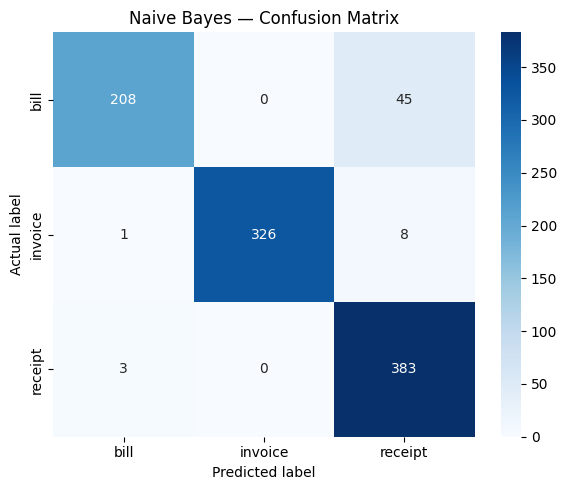


TRAINING: SVM
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters:
{'model__C': 2.0, 'tfidf__ngram_range': (1, 2)}

Best CV macro-F1: 0.9514
Test accuracy:    0.9589 (95.89%)
Test macro-F1:    0.9577
Test weighted-F1: 0.9591

Classification report:
              precision    recall  f1-score   support

        bill     0.9333    0.9407    0.9370       253
     invoice     0.9970    0.9761    0.9864       335
     receipt     0.9437    0.9560    0.9498       386

    accuracy                         0.9589       974
   macro avg     0.9580    0.9576    0.9577       974
weighted avg     0.9593    0.9589    0.9591       974

Confusion matrix (rows = actual, columns = predicted):
                Predicted bill  Predicted invoice  Predicted receipt
Actual bill                238                  0                 15
Actual invoice               1                327                  7
Actual receipt              16                  1                369
Saved model: 

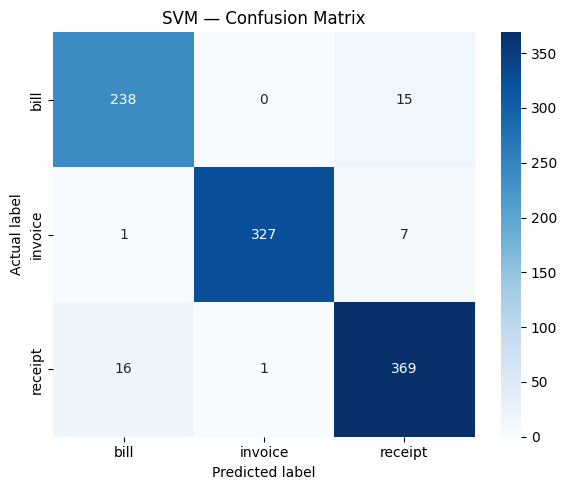


TRAINING: CatBoost
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Best parameters:
{'model__depth': 6, 'model__iterations': 200, 'model__learning_rate': 0.1, 'tfidf__ngram_range': (1, 1)}

Best CV macro-F1: 0.9381
Test accuracy:    0.9456 (94.56%)
Test macro-F1:    0.9428
Test weighted-F1: 0.9455

Classification report:
              precision    recall  f1-score   support

        bill     0.9522    0.8656    0.9068       253
     invoice     1.0000    0.9731    0.9864       335
     receipt     0.8995    0.9741    0.9353       386

    accuracy                         0.9456       974
   macro avg     0.9506    0.9376    0.9428       974
weighted avg     0.9478    0.9456    0.9455       974

Confusion matrix (rows = actual, columns = predicted):
                Predicted bill  Predicted invoice  Predicted receipt
Actual bill                219                  0                 34
Actual invoice               1                326                  8
Actual receipt       

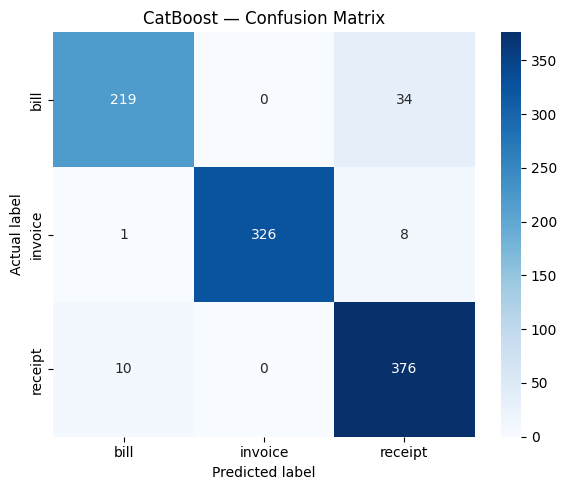


FINAL MODEL COMPARISON


,Model,Accuracy,Macro_F1,Weighted_F1,Best_CV_Macro_F1,Best_Parameters
0,SVM,0.958932,0.957747,0.959077,0.951389,"{'model__C': 2.0, 'tfidf__ngram_range': (1, 2)}"
1,CatBoost,0.945585,0.942847,0.945485,0.938143,"{'model__depth': 6, 'model__iterations': 200, ..."
2,Naive Bayes,0.941478,0.937627,0.940946,0.933963,"{'model__alpha': 0.1, 'tfidf__ngram_range': (1..."


Comparison saved to: /content/model_comparison_results.csv

Best model by test macro-F1: SVM
Remember: this is a held-out test result, not a guarantee of performance on new real-world documents.

Saved model files:
/content/saved_models/catboost.joblib
/content/saved_models/naive_bayes.joblib
/content/saved_models/svm.joblib


In [ ]:

# ============================================================
# MODEL TRAINING AND EVALUATION
# Models: Multinomial Naive Bayes, SVM, CatBoost
# Metrics: Accuracy, Classification Report, Confusion Matrix
# ============================================================

!pip -q install catboost scikit-learn joblib matplotlib seaborn

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE DATASET
# ------------------------------------------------------------

DATASET_PATH = "/content/combined_document_dataset.csv"
MODEL_DIR = "/content/saved_models"

os.makedirs(MODEL_DIR, exist_ok=True)

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}. "
        "Run the dataset integration cell first."
    )

df = pd.read_csv(DATASET_PATH)

required_columns = ["text", "class_label"]

if not all(col in df.columns for col in required_columns):
    raise ValueError(
        f"Dataset must contain exactly the required fields: "
        f"{required_columns}. Found: {df.columns.tolist()}"
    )

df = df[required_columns].copy()
df["text"] = df["text"].fillna("").astype(str).str.strip()
df["class_label"] = (
    df["class_label"].fillna("").astype(str).str.strip().str.lower()
)

df = df[
    df["text"].ne("") &
    df["class_label"].isin(["receipt", "invoice", "bill"])
].copy()

# Remove exact duplicate text before splitting to reduce leakage.
df["_normalized_text"] = (
    df["text"].str.replace(r"\s+", " ", regex=True).str.casefold()
)
df = df.drop_duplicates(subset=["_normalized_text"]).copy()
df = df.drop(columns=["_normalized_text"]).reset_index(drop=True)

print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)
print("Total samples:", len(df))
print("\nClass distribution:")
print(df["class_label"].value_counts())

if df["class_label"].nunique() != 3:
    raise ValueError(
        "All three classes (receipt, invoice, bill) must be present."
    )

# Each class needs enough samples for a stratified split and CV.
class_counts = df["class_label"].value_counts()

if class_counts.min() < 5:
    raise ValueError(
        "At least 5 unique examples per class are required for this "
        "evaluation setup. Current counts:\n"
        + class_counts.to_string()
    )

# ------------------------------------------------------------
# 2. TRAIN / TEST SPLIT
# ------------------------------------------------------------

X = df["text"]
y = df["class_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

labels = ["bill", "invoice", "receipt"]

# Use CV folds compatible with the smallest training class.
min_train_class = int(y_train.value_counts().min())
cv_folds = min(3, min_train_class)

cv = StratifiedKFold(
    n_splits=cv_folds,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. DEFINE THREE MODELS AND SEARCH SPACES
# TF-IDF is fitted independently inside each pipeline/fold.
# ------------------------------------------------------------

models = {
    "Naive Bayes": {
        "pipeline": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                sublinear_tf=True,
                max_features=30000
            )),
            ("model", MultinomialNB())
        ]),
        "params": {
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "model__alpha": [0.1, 0.5, 1.0]
        }
    },

    "SVM": {
        "pipeline": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                sublinear_tf=True,
                max_features=30000
            )),
            ("model", LinearSVC(
                random_state=42,
                max_iter=5000
            ))
        ]),
        "params": {
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "model__C": [0.5, 1.0, 2.0]
        }
    },

    "CatBoost": {
        "pipeline": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                sublinear_tf=True,
                max_features=15000
            )),
            ("model", CatBoostClassifier(
                loss_function="MultiClass",
                verbose=0,
                random_seed=42,
                thread_count=-1,
                allow_writing_files=False
            ))
        ]),
        "params": {
            "tfidf__ngram_range": [(1, 1)],
            "model__iterations": [200],
            "model__depth": [4, 6],
            "model__learning_rate": [0.1]
        }
    }
}

# ------------------------------------------------------------
# 4. TRAIN, TUNE AND EVALUATE
# ------------------------------------------------------------

results = []
trained_models = {}
confusion_matrices = {}

for model_name, config in models.items():

    print("\n" + "=" * 70)
    print(f"TRAINING: {model_name}")
    print("=" * 70)

    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["params"],
        scoring="f1_macro",
        cv=cv,
        n_jobs=1,
        refit=True,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    print("\nBest parameters:")
    print(search.best_params_)

    print(f"\nBest CV macro-F1: {search.best_score_:.4f}")
    print(f"Test accuracy:    {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Test macro-F1:    {macro_f1:.4f}")
    print(f"Test weighted-F1: {weighted_f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=labels,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    confusion_matrices[model_name] = cm

    print("Confusion matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(
        cm,
        index=[f"Actual {x}" for x in labels],
        columns=[f"Predicted {x}" for x in labels]
    ))

    # Save each tuned model pipeline, including its TF-IDF vectorizer.
    model_path = os.path.join(
        MODEL_DIR,
        model_name.lower().replace(" ", "_") + ".joblib"
    )
    joblib.dump(best_model, model_path)
    trained_models[model_name] = best_model

    print("Saved model:", model_path)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Best_CV_Macro_F1": search.best_score_,
        "Best_Parameters": str(search.best_params_)
    })

    # One confusion matrix per model.
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. COMPARE THE MODELS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

results_df = pd.DataFrame(results).sort_values(
    by="Macro_F1", ascending=False
).reset_index(drop=True)

display(results_df)

results_path = "/content/model_comparison_results.csv"
results_df.to_csv(results_path, index=False)

print("Comparison saved to:", results_path)

best_name = results_df.iloc[0]["Model"]

print(f"\nBest model by test macro-F1: {best_name}")
print(
    "Remember: this is a held-out test result, not a guarantee "
    "of performance on new real-world documents."
)

print("\nSaved model files:")
for file_name in sorted(os.listdir(MODEL_DIR)):
    print(os.path.join(MODEL_DIR, file_name))


In [ ]:
%%writefile app.py
import streamlit as st
import pickle
import pdfplumber
import re

def clean_text(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s$.,%/\-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

@st.cache_resource
def load_artifacts():
    with open('model.pkl', 'rb') as f:
        artifact = pickle.load(f)
    return artifact['vectorizer'], artifact['model']

vectorizer, model = load_artifacts()

st.title("📄 PDF Document Classifier (CatBoost)")
st.write("Upload an Invoice, Bill, or Receipt PDF to extract text and classify.")

uploaded_file = st.file_uploader("Choose a PDF file", type=["pdf"])

if uploaded_file is not None:
    raw_text = ""
    with pdfplumber.open(uploaded_file) as pdf:
        for page in pdf.pages:
            t = page.extract_text()
            if t:
                raw_text += t + "\n"

    if raw_text.strip():
        processed_text = clean_text(raw_text)

        st.subheader("Extracted & Preprocessed Text")
        st.text_area("Content", processed_text, height=180)

        # Transform and Predict
        features = vectorizer.transform([processed_text]).toarray()
        prediction = model.predict(features)[0]

        if isinstance(prediction, (list, np.ndarray)):
            prediction = prediction[0]

        st.success(f"**Predicted Category:** {prediction}")
    else:
        st.error("Could not extract text from this PDF.")

Overwriting app.py


In [ ]:
%%writefile app.py
import streamlit as st
import pickle
import pdfplumber
import re
import numpy as np

def clean_text(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s$.,%/\-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

@st.cache_resource
def load_artifacts():
    with open('model.pkl', 'rb') as f:
        artifact = pickle.load(f)
    # Unpack the dictionary saved during training
    return artifact['vectorizer'], artifact['model'], artifact['mapping']

vectorizer, model, inv_mapping = load_artifacts()

st.title("📄 PDF Document Classifier")
st.write("Upload an Invoice, Bill, or Receipt PDF to classify its document type.")

uploaded_file = st.file_uploader("Choose a PDF file", type=["pdf"])

if uploaded_file is not None:
    raw_text = ""
    with pdfplumber.open(uploaded_file) as pdf:
        for page in pdf.pages:
            t = page.extract_text()
            if t:
                raw_text += t + "\n"

    if raw_text.strip():
        processed_text = clean_text(raw_text)

        st.subheader("Extracted & Preprocessed Text Preview")
        st.text_area("Content", processed_text, height=150)

        # 1. Vectorize text
        features = vectorizer.transform([processed_text]).toarray()

        # 2. Predict numeric class
        pred_idx = model.predict(features)[0]
        if isinstance(pred_idx, (list, np.ndarray)):
            pred_idx = int(pred_idx[0])
        else:
            pred_idx = int(pred_idx)

        # 3. Map back to string label ('Bill', 'Invoice', 'Receipt')
        predicted_label = inv_mapping.get(pred_idx, "Unknown")

        st.success(f"**Predicted Category:** {predicted_label}")
    else:
        st.error("Could not extract text from this PDF.")

Overwriting app.py


In [ ]:
!curl ipv4.icanhazip.com

34.12.0.16


In [ ]:
!streamlit run app.py &> /dev/null &

In [ ]:
import subprocess
from google.colab import userdata
from pyngrok import ngrok

# 1. Fetch token securely from Colab Secrets
NGROK_TOKEN = userdata.get("NGROK_AUTH_TOKEN")
ngrok.set_auth_token(NGROK_TOKEN)

# 2. Terminate old sessions
ngrok.kill()
subprocess.Popen(["pkill", "-f", "streamlit"])

# 3. Connect ngrok tunnel
public_url = ngrok.connect(8501)
print(f"\n🚀 Your Streamlit App is live at: {public_url}\n")

# 4. Launch Streamlit
!streamlit run app.py &> /dev/null &


🚀 Your Streamlit App is live at: NgrokTunnel: "https://dictate-dandelion-bulginess.ngrok-free.dev" -> "http://localhost:8501"



In [ ]:
import subprocess
from pyngrok import ngrok

# 1. Kill any lingering streamlit or ngrok processes
!pkill -f streamlit
ngrok.kill()

# 2. Start Streamlit in the background pointing to your app.py
subprocess.Popen(["streamlit", "run", "app.py", "--server.port=8501"])

# 3. Create a fresh public ngrok URL
public_url = ngrok.connect(8501)
print(f"🚀 Your New Live Streamlit URL: {public_url}")

🚀 Your New Live Streamlit URL: NgrokTunnel: "https://dictate-dandelion-bulginess.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
%%writefile app.py
import streamlit as st
import joblib
import pdfplumber
import re
import numpy as np
import os
from PIL import Image
import pytesseract

# Securely load the best performing model from training
@st.cache_resource
def load_model_artifacts():
    # Using the best classifier found on held-out test data (SVM with 95.89% accuracy)
    model_path = '/content/saved_models/svm.joblib'
    if not os.path.exists(model_path):
        # Fallback to naive bayes if svm is missing
        model_path = '/content/saved_models/naive_bayes.joblib'

    model_pipeline = joblib.load(model_path)
    return model_pipeline, os.path.basename(model_path).replace('.joblib', '').upper()

pipeline, model_name = load_model_artifacts()

def clean_text(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s$.,%/\-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

st.set_page_colab = True
st.title("📄 Document Type Classifier (OCR-Enabled)")
st.write(f"Upload a PDF or an Image (Invoice, Bill, or Receipt) to automatically extract text and classify using our trained **{model_name}** model.")

uploaded_file = st.file_uploader("Choose a PDF or Document Image", type=["pdf", "png", "jpg", "jpeg", "tiff"])

if uploaded_file is not None:
    raw_text = ""
    file_name = uploaded_file.name
    file_ext = os.path.splitext(file_name)[1].lower()

    with st.spinner("Processing file and extracting text..."):
        if file_ext == ".pdf":
            try:
                with pdfplumber.open(uploaded_file) as pdf:
                    for page in pdf.pages:
                        t = page.extract_text()
                        if t:
                            raw_text += t + "\n"
            except Exception as e:
                st.error(f"Error parsing PDF: {e}")
        else:
            # Process document images (PNG, JPG, JPEG, TIFF)
            try:
                img = Image.open(uploaded_file)
                raw_text = pytesseract.image_to_string(img.convert("RGB"))
            except Exception as e:
                st.error(f"Error performing OCR on image: {e}")

    if raw_text.strip():
        processed_text = clean_text(raw_text)

        st.subheader("Extracted & Cleaned Text Preview")
        st.text_area("Document Content", processed_text, height=180)

        # Use our loaded sklearn vectorizer pipeline to transform & predict directly
        prediction = pipeline.predict([processed_text])[0]

        st.success(f"**Predicted Category:** {prediction.upper()}")
    else:
        st.error("Could not extract readable text from this file. Ensure the document is not empty or corrupted.")


Overwriting app.py


In [ ]:
# Ensure all system and Python package dependencies are pre-installed
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip install -q pdfplumber streamlit pyngrok pytesseract joblib pillow

import sys
import subprocess
from pyngrok import ngrok
from google.colab import userdata

# 1. Fetch token securely from Colab Secrets and authenticate
try:
    NGROK_TOKEN = userdata.get("NGROK_AUTH_TOKEN")
    ngrok.set_auth_token(NGROK_TOKEN)
except Exception as e:
    print(f"⚠️ Warning fetching NGROK_AUTH_TOKEN: {e}\nMake sure to add it under the Secrets tab in Colab!")

# 2. Terminate old processes
!pkill -f streamlit
ngrok.kill()

# 3. Restart Streamlit using the current python executable module path
subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.port=8501"])

# 4. Create public Tunnel
public_url = ngrok.connect(8501)
print(f"🚀 Streamlit App successfully updated and verified!")
print(f"🔗 Access your new OCR-enabled App here: {public_url}")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 601.4 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 94.9 MB/s eta 0:00:00
🚀 Streamlit App successfully updated and verified!
🔗 Access your new OCR-enabled App here: NgrokTunnel: "https://dictate-dandelion-bulginess.ngrok-free.dev" -> "http://localhost:8501"
